# Лабораторная работа № 4 — вариант 6
## Применение РНН для анализа временных рядов
**ФИО:** Работин М.А.  
**Номер зачётной книжки:** 230356  
**Группа:** МОА-231  
**Вариант:** 6  
**Объект:** ежеминутный датчик температуры  
**История наблюдений:** 1440 минут (24 ч) · **горизонт прогноза:** 2880 минут (48 ч)

В учебном примере используется синтетический ряд на 60 суток, а не реальные измерения. Если преподаватель требует реальные данные датчика, замените генератор в разделе 2 чтением CSV. По методичке вычисления можно выполнять на CPU; устройство ниже автоматически выбирает CUDA, если она доступна. Чтобы строго использовать CPU, установите `DEVICE = torch.device("cpu")`.

Выполняйте ячейки сверху вниз. После завершения сохраните ноутбук вместе с таблицами и графиками из каталога `outputs/`.

## 1. Импорты, seed и конфигурация

In [1]:
import random, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
SEED, VARIANT = 42, 6
GRID, WINDOW, HORIZON, SEASONAL_PERIOD = '1min', 1440, 2880, 1440
LEADS = [1, 60, 360, 1440, 2880]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()
print(f'Вариант {VARIANT} | температура | WINDOW={WINDOW} | HORIZON={HORIZON} | {DEVICE}')
if DEVICE.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

Вариант 6 | температура | WINDOW=1440 | HORIZON=2880 | cpu


## 2. Учебный ряд и предварительный анализ
В реальном проекте замените функцию генерации чтением CSV с timestamp и значением датчика.

Точек: 86400 Пропусков после обработки: 0


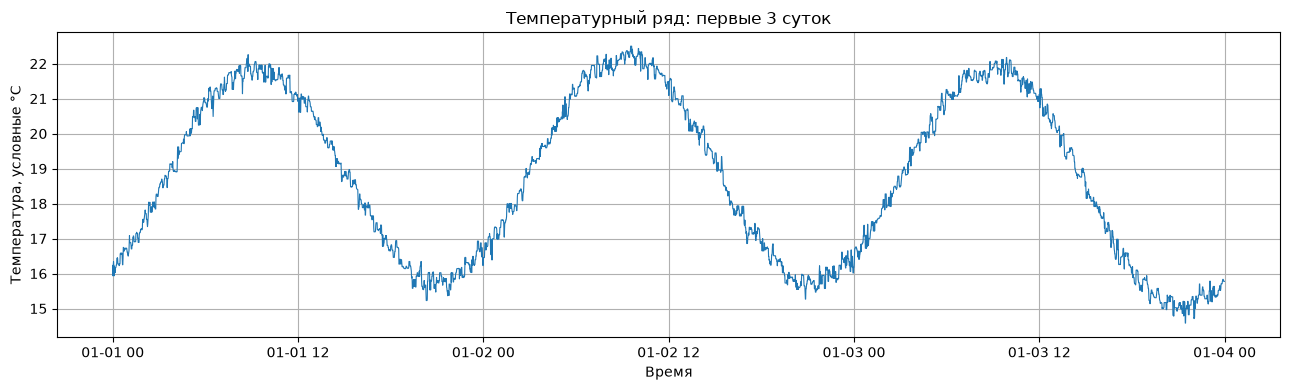

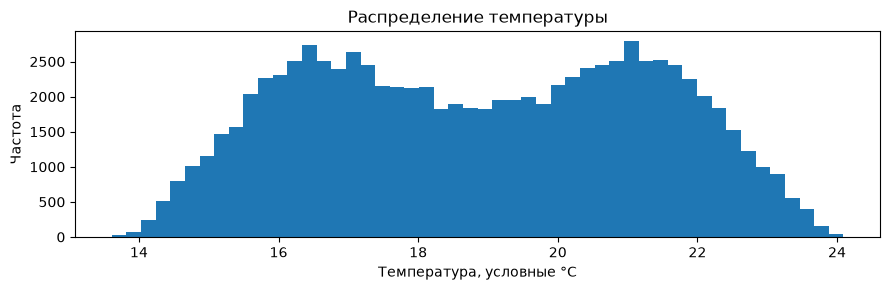

In [2]:
def make_synthetic_minute_series(n_days=60, seed=SEED):
    rng=np.random.default_rng(seed); n=n_days*1440; t=np.arange(n)
    daily=3.2*np.sin(2*np.pi*t/1440-0.8)
    weekly=1.0*np.sin(2*np.pi*t/(7*1440)+0.4)
    trend=0.00002*t; noise=rng.normal(0,0.45,n)
    idx=pd.date_range('2026-01-01', periods=n, freq=GRID)
    return pd.Series(18+daily+weekly+trend+noise,index=idx,name='temperature')
series=make_synthetic_minute_series()
# Демонстрируем пропуски и предусмотренную вариантом 6 медианную обработку (окно 6+3=9).
rng=np.random.default_rng(SEED+1); with_gaps=series.copy()
with_gaps.iloc[rng.choice(len(series),50,replace=False)]=np.nan
series=with_gaps.rolling(VARIANT+3,min_periods=1).median().ffill().bfill()
print('Точек:',len(series),'Пропусков после обработки:',int(series.isna().sum()))
fig,ax=plt.subplots(figsize=(13,4)); ax.plot(series.index[:4320],series.iloc[:4320],lw=.8)
ax.set(title='Температурный ряд: первые 3 суток',xlabel='Время',ylabel='Температура, условные °C'); ax.grid(); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(9,3)); ax.hist(series,bins=50); ax.set(title='Распределение температуры',xlabel='Температура, условные °C',ylabel='Частота'); plt.tight_layout(); plt.show()

## 3. Декомпозиция, ADF, ACF и PACF
Методичка для варианта 6 указывает дифференцирование порядка VARIANT+1=7. Сравниваем его с первой разностью: высокие порядки могут чрезмерно преобразовать ряд.

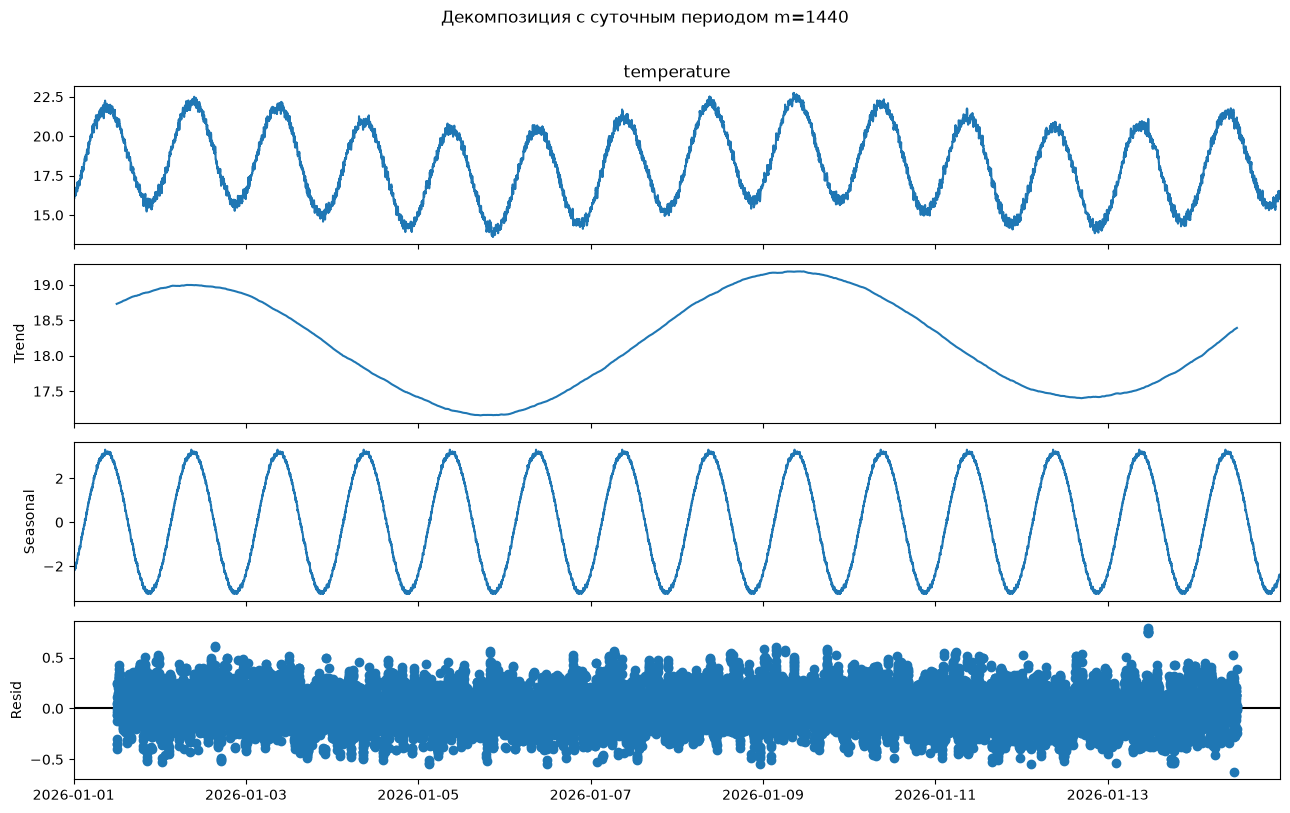

Исходный ряд: ADF=-1.992, p-value=0.29005
Первая разность: ADF=-11.531, p-value=3.8394e-21
Разность порядка 7: ADF=-9.174, p-value=2.3519e-15


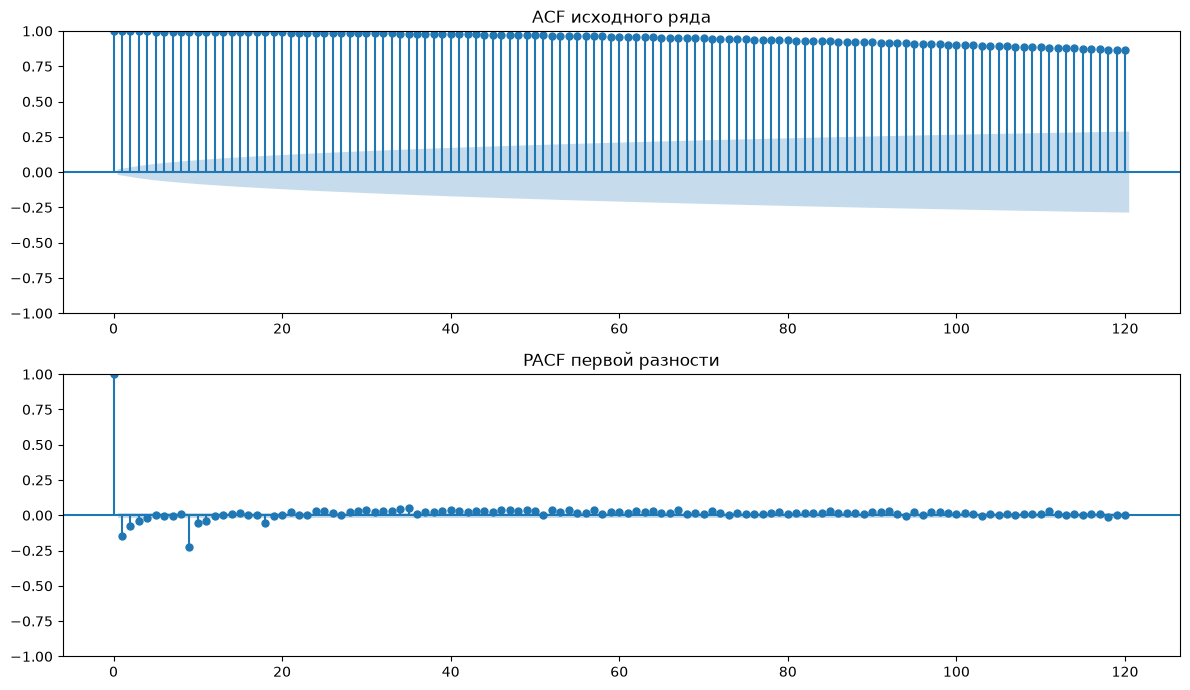

In [3]:
dec=seasonal_decompose(series.iloc[:14*1440],model='additive',period=SEASONAL_PERIOD)
fig=dec.plot(); fig.set_size_inches(13,8); fig.suptitle('Декомпозиция с суточным периодом m=1440',y=1.01); plt.tight_layout(); plt.show()
def adf_report(x,label):
    stat,p,*_=adfuller(pd.Series(x).dropna().to_numpy(),autolag='AIC',result_object=False)
    print(f'{label}: ADF={stat:.3f}, p-value={p:.5g}')
adf_report(series.iloc[:7*1440],'Исходный ряд')
adf_report(series.diff().dropna().iloc[:7*1440],'Первая разность')
adf_report(series.diff(VARIANT+1).dropna().iloc[:7*1440],'Разность порядка 7')
fig,axes=plt.subplots(2,1,figsize=(12,7)); plot_acf(series.iloc[:7*1440],lags=120,ax=axes[0]); axes[0].set_title('ACF исходного ряда')
plot_pacf(series.diff().dropna().iloc[:7*1440],lags=120,method='ywm',ax=axes[1]); axes[1].set_title('PACF первой разности'); plt.tight_layout(); plt.show()

## 4. Хронологические train/validation/test и контроль утечки
Разделение 70/15/15 выполняется с зазорами по 2880 точек. Масштабирование обучается только на train.

In [4]:
raw=series.to_numpy(dtype=np.float32); n=len(raw); usable=n-2*HORIZON
ntr=int(usable*.70); nva=int(usable*.15)
tr=slice(0,ntr); va=slice(ntr+HORIZON,ntr+HORIZON+nva); te=slice(va.stop+HORIZON,n)
scaler=StandardScaler().fit(raw[tr].reshape(-1,1))
scaled=scaler.transform(raw.reshape(-1,1)).ravel().astype(np.float32)
mu,sd=float(scaler.mean_[0]),float(scaler.scale_[0])
print('Размеры частей:',len(raw[tr]),len(raw[va]),len(raw[te]))
print('Границы train/val/test:',series.index[tr.stop-1],series.index[va.start],series.index[te.start])
assert tr.stop+HORIZON<=va.start and va.stop+HORIZON<=te.start
print('Проверки: хронология соблюдена; scaler fit только на train; зазор = HORIZON.')
def window_starts(split):
    first=split.start+WINDOW; last=split.stop-HORIZON
    return np.arange(first,last+1,dtype=np.int64) if last>=first else np.array([],dtype=np.int64)
train_starts,val_starts,test_starts=map(window_starts,(tr,va,te))
print('Доступные окна:',len(train_starts),len(val_starts),len(test_starts))

Размеры частей: 56448 12096 12096
Границы train/val/test: 2026-02-09 04:47:00 2026-02-11 04:48:00 2026-02-21 14:24:00
Проверки: хронология соблюдена; scaler fit только на train; зазор = HORIZON.
Доступные окна: 52129 7777 7777


## 5. Базовые модели
Сравниваем на общем тестовом горизонте: наивную, сезонную наивную, ETS, ARIMA и градиентный бустинг на лагах. Дорогие модели ограничены последними днями истории.

In [5]:
def naive_forecast(h,horizon=HORIZON): return np.repeat(float(h[-1]),horizon)
def seasonal_naive_forecast(h,horizon=HORIZON,m=1440):
    return np.tile(h[-m:],int(np.ceil(horizon/m)))[:horizon] if len(h)>=m else naive_forecast(h,horizon)
def ets_forecast(h,horizon=HORIZON):
    return np.asarray(ExponentialSmoothing(h[-7*1440:],trend='add',seasonal=None,initialization_method='estimated').fit().forecast(horizon))
def arima_forecast(h,horizon=HORIZON):
    sample=np.asarray(h[-3*1440:],float); best=(1,1,0); best_aic=np.inf
    for p in range(3):
        for q in range(3):
            try:
                fit=ARIMA(sample,order=(p,1,q)).fit()
                if fit.aic<best_aic: best_aic,best=fit.aic,(p,1,q)
            except Exception: pass
    return np.asarray(ARIMA(sample,order=best).fit().forecast(horizon))
def gb_forecast(h,horizon=HORIZON):
    y=np.asarray(h[-14*1440:],np.float32); lags=[1,60,1440]; start=max(lags); t=np.arange(len(y))
    X=np.column_stack([y[start-len(y)+lag:len(y)-lag] for lag in []]) if False else np.column_stack([np.roll(y,lag)[start:] for lag in lags]+[(t[start:]//60)%24,(t[start:]//1440)%7])
    model=HistGradientBoostingRegressor(max_iter=60,max_leaf_nodes=15,random_state=SEED).fit(X,y[start:])
    buf=list(y); out=[]
    for step in range(horizon):
        k=len(y)+step; feat=[[buf[-lag] for lag in lags]+[(k//60)%24,(k//1440)%7]]
        p=float(model.predict(feat)[0]); out.append(p); buf.append(p)
    return np.asarray(out)
def metrics(name,truth,pred,hist):
    pred=np.asarray(pred)[:len(truth)]; scale=np.mean(np.abs(hist[1440:]-hist[:-1440]))+1e-8
    err=truth-pred
    return {'Модель':name,'MAE':mean_absolute_error(truth,pred),'RMSE':mean_squared_error(truth,pred)**.5,'MASE':mean_absolute_error(truth,pred)/scale,'Pinball tau=0.5':np.maximum(.5*err,-.5*err).mean()}
test_origin=te.start; history=raw[:test_origin]; y_true=raw[test_origin:test_origin+HORIZON]
if len(y_true)!=HORIZON: raise ValueError('Тестовая часть короче полного горизонта')
funcs={'Наивная':naive_forecast,'Сезонная наивная':seasonal_naive_forecast,'ETS':ets_forecast,'ARIMA':arima_forecast,'Gradient Boosting':gb_forecast}
predictions={}; rows=[]
for name,fn in funcs.items():
    tic=time.perf_counter()
    try:
        pred=fn(history); predictions[name]=pred; row=metrics(name,y_true,pred,history); row['Время, сек']=time.perf_counter()-tic; rows.append(row)
        print(name,'MAE=',round(row['MAE'],4),'RMSE=',round(row['RMSE'],4))
    except Exception as e: print('Пропускаем',name,type(e).__name__,str(e)[:200])
baseline_table=pd.DataFrame(rows).sort_values('MAE'); display(baseline_table)

Наивная MAE= 2.1189 RMSE= 2.5708
Сезонная наивная MAE= 1.0882 RMSE= 1.1755
ETS MAE= 10.0176 RMSE= 12.0787
ARIMA MAE= 2.1159 RMSE= 2.5658
Gradient Boosting MAE= 1.4748 RMSE= 1.751


,Модель,MAE,RMSE,MASE,Pinball tau=0.5,"Время, сек"
1,Сезонная наивная,1.088200,1.175477,1.914836,0.544100,0.001183
4,Gradient Boosting,1.474759,1.750970,2.595040,0.737380,1.740472
3,ARIMA,2.115915,2.565775,3.723241,1.057957,3.648854
0,Наивная,2.118936,2.570787,3.728557,1.059468,0.001549
2,ETS,10.017577,12.078662,17.627295,5.008789,0.303066


## 6. LSTM и GRU
Каждая сеть получает окно из 1440 значений и предсказывает весь горизонт из 2880 значений одним выходом. Для приемлемого времени используется детерминированная подвыборка окон.

In [6]:
class WindowDataset(torch.utils.data.Dataset):
    def __init__(self,values,starts): self.values,self.starts=values,starts
    def __len__(self): return len(self.starts)
    def __getitem__(self,i):
        end=int(self.starts[i]); return torch.from_numpy(self.values[end-WINDOW:end,None].copy()),torch.from_numpy(self.values[end:end+HORIZON].copy())
class RNNForecaster(nn.Module):
    def __init__(self,cell='lstm',hidden=32):
        super().__init__(); rnn=nn.LSTM if cell=='lstm' else nn.GRU
        self.rnn=rnn(1,hidden,batch_first=True); self.head=nn.Sequential(nn.Linear(hidden,128),nn.ReLU(),nn.Linear(128,HORIZON))
    def forward(self,x): return self.head(self.rnn(x)[0][:,-1])
def train_rnn(model,train_loader,val_loader,epochs=5,patience=2):
    opt=torch.optim.Adam(model.parameters(),lr=1e-3); loss_fn=nn.HuberLoss(); best=np.inf; best_state=None; wait=0; hist={'train':[],'val':[]}
    for epoch in range(1,epochs+1):
        tic=time.perf_counter(); model.train(); tl=[]
        for xb,yb in train_loader:
            opt.zero_grad(set_to_none=True); loss=loss_fn(model(xb.to(DEVICE)),yb.to(DEVICE)); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); tl.append(loss.item())
        model.eval(); vl=[]
        with torch.no_grad():
            for xb,yb in val_loader: vl.append(loss_fn(model(xb.to(DEVICE)),yb.to(DEVICE)).item())
        a,b=float(np.mean(tl)),float(np.mean(vl)); hist['train'].append(a); hist['val'].append(b)
        print(f'Epoch {epoch}/{epochs}: train={a:.4f} val={b:.4f} time={time.perf_counter()-tic:.1f}s')
        if b<best: best=b; best_state={k:v.detach().clone() for k,v in model.state_dict().items()}; wait=0
        else:
            wait+=1
            if wait>=patience: print('Early stopping'); break
    if best_state: model.load_state_dict(best_state)
    return hist
# Равномерно берём максимум 800 train-окон и 100 validation-окон.
train_sel=train_starts[::max(1,len(train_starts)//800)][:800]; val_sel=val_starts[::max(1,len(val_starts)//100)][:100]
train_loader=torch.utils.data.DataLoader(WindowDataset(scaled,train_sel),batch_size=8,shuffle=True,num_workers=0)
val_loader=torch.utils.data.DataLoader(WindowDataset(scaled,val_sel),batch_size=8,shuffle=False,num_workers=0)
rnn_rows=[]; rnn_models={}; rnn_histories={}; rnn_predictions={}
for cell in ['lstm','gru']:
    print('Обучение',cell.upper()); set_seed(); model=RNNForecaster(cell).to(DEVICE); tic=time.perf_counter()
    hist=train_rnn(model,train_loader,val_loader,epochs=5,patience=2); elapsed=time.perf_counter()-tic
    x=torch.from_numpy(scaled[test_origin-WINDOW:test_origin,None].copy()).unsqueeze(0)
    model.eval()
    with torch.no_grad(): pred=model(x.to(DEVICE)).cpu().numpy().ravel()*sd+mu
    name=cell.upper(); rnn_models[name]=model; rnn_histories[name]=hist; rnn_predictions[name]=pred
    row=metrics(name,y_true,pred,history); row['Время, сек']=elapsed; rnn_rows.append(row)
rnn_table=pd.DataFrame(rnn_rows); display(rnn_table)

Обучение LSTM
Epoch 1/5: train=0.3464 val=0.2909 time=4.7s
Epoch 2/5: train=0.2876 val=0.2867 time=4.7s
Epoch 3/5: train=0.2870 val=0.2907 time=4.6s
Epoch 4/5: train=0.2852 val=0.2940 time=4.7s
Early stopping
Обучение GRU
Epoch 1/5: train=0.3320 val=0.2896 time=28.2s
Epoch 2/5: train=0.2875 val=0.2951 time=30.0s
Epoch 3/5: train=0.2861 val=0.2890 time=29.7s
Epoch 4/5: train=0.2853 val=0.2831 time=29.8s
Epoch 5/5: train=0.2844 val=0.2862 time=29.8s


,Модель,MAE,RMSE,MASE,Pinball tau=0.5,"Время, сек"
0,LSTM,2.084293,2.367058,3.667599,1.042147,20.151869
1,GRU,2.068267,2.356807,3.639398,1.034134,147.612400


## 7. Сравнение, ошибки по горизонту и график прогноза

,Модель,MAE,RMSE,MASE,Pinball tau=0.5,"Время, сек"
0,Сезонная наивная,1.088200,1.175477,1.914836,0.544100,0.001183
1,Gradient Boosting,1.474759,1.750970,2.595040,0.737380,1.740472
6,GRU,2.068267,2.356807,3.639398,1.034134,147.612400
5,LSTM,2.084293,2.367058,3.667599,1.042147,20.151869
2,ARIMA,2.115915,2.565775,3.723241,1.057957,3.648854
3,Наивная,2.118936,2.570787,3.728557,1.059468,0.001549
4,ETS,10.017577,12.078662,17.627295,5.008789,0.303066


,Горизонт,Абсолютная ошибка
0,1 минута,0.268265
1,1 час,0.644737
2,6 часов,0.797535
3,24 часа,0.952785
4,48 часов,1.189859


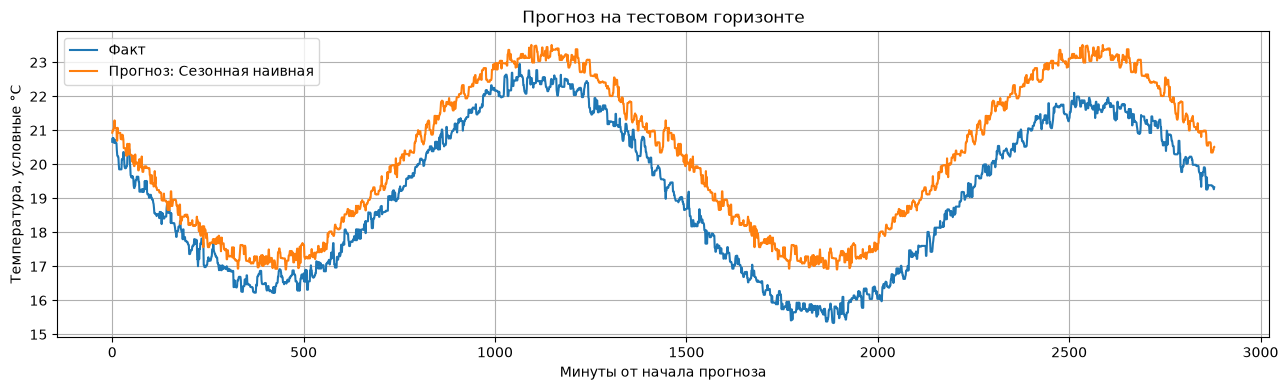

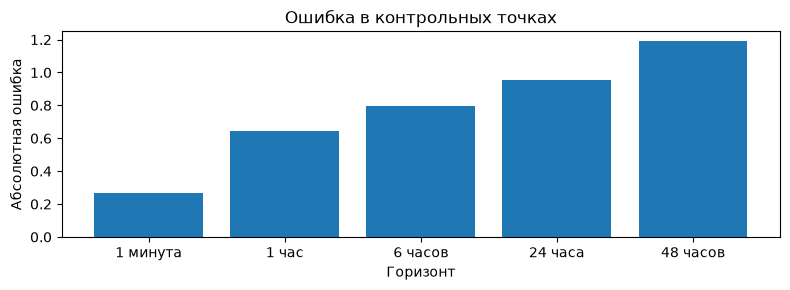

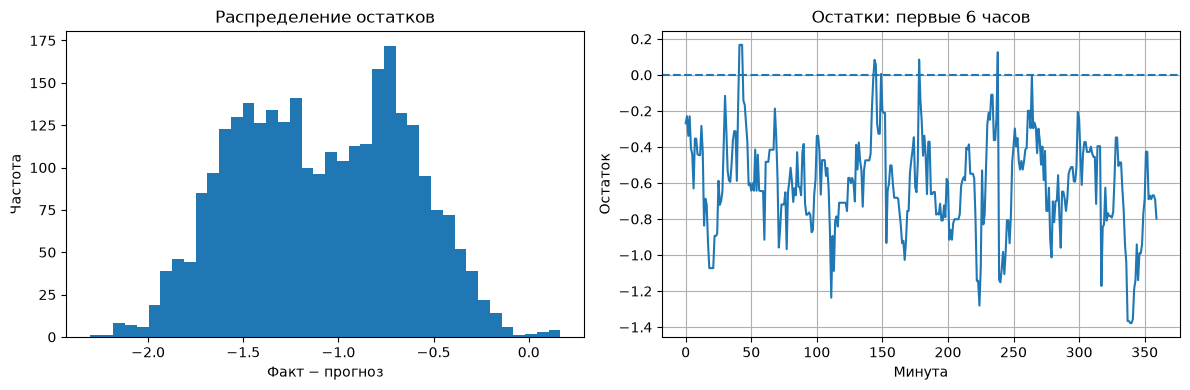

Средний остаток: -1.0876051187515259 | std: 0.4459371268749237


In [7]:
comparison=pd.concat([baseline_table,rnn_table],ignore_index=True).sort_values('MAE'); display(comparison)
comparison.to_csv(OUT/'final_metrics.csv',index=False)
all_predictions={**predictions,**rnn_predictions}; best_name=str(comparison.iloc[0]['Модель']); best_pred=all_predictions[best_name]
lead_names={1:'1 минута',60:'1 час',360:'6 часов',1440:'24 часа',2880:'48 часов'}
lead_table=pd.DataFrame([{'Горизонт':lead_names[k],'Абсолютная ошибка':abs(float(y_true[k-1]-best_pred[k-1]))} for k in LEADS]); display(lead_table)
show_n=2880; fig,ax=plt.subplots(figsize=(13,4)); ax.plot(y_true[:show_n],label='Факт'); ax.plot(best_pred[:show_n],label=f'Прогноз: {best_name}'); ax.set(title='Прогноз на тестовом горизонте',xlabel='Минуты от начала прогноза',ylabel='Температура, условные °C'); ax.legend(); ax.grid(); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8,3)); ax.bar(lead_table['Горизонт'],lead_table['Абсолютная ошибка']); ax.set(title='Ошибка в контрольных точках',xlabel='Горизонт',ylabel='Абсолютная ошибка'); plt.tight_layout(); plt.show()
resid=y_true-best_pred; fig,axes=plt.subplots(1,2,figsize=(12,4)); axes[0].hist(resid,bins=40); axes[0].set(title='Распределение остатков',xlabel='Факт − прогноз',ylabel='Частота'); axes[1].plot(resid[:360]); axes[1].axhline(0,ls='--'); axes[1].set(title='Остатки: первые 6 часов',xlabel='Минута',ylabel='Остаток'); axes[1].grid(); plt.tight_layout(); plt.show()
print('Средний остаток:',float(resid.mean()),'| std:',float(resid.std()))

## 8. Walk-forward backtesting и кривые обучения
Для компактного запуска backtesting выполняется для двух быстрых наивных ориентиров. Нейросети сравниваются на едином тестовом горизонте; полное переобучение нейросетей на каждом фолде существенно увеличило бы время.

,Модель,MAE,RMSE,MASE,Pinball tau=0.5
0,Наивная,2.914944,3.597871,5.088664,1.457472
1,Наивная,2.722651,3.416640,4.764625,1.361326
2,Наивная,2.436424,2.881297,4.263110,1.218212
3,Сезонная наивная,0.607643,0.771700,1.060771,0.303821
4,Сезонная наивная,0.939222,1.012497,1.643633,0.469611
5,Сезонная наивная,0.884897,1.016195,1.548339,0.442448


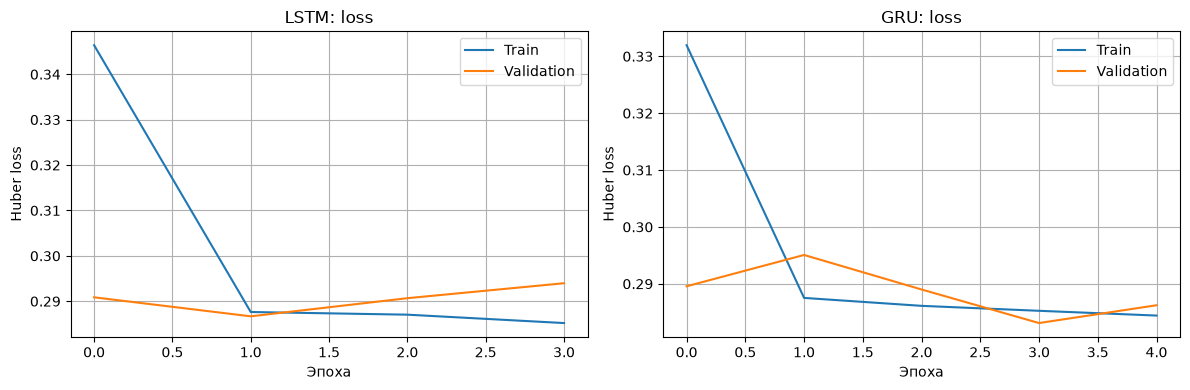

In [8]:
def backtest(values,fn,n_folds=3,horizon=HORIZON):
    initial=len(values)-n_folds*horizon; out=[]
    for k in range(n_folds):
        end=initial+k*horizon; hist=values[:end]; truth=values[end:end+horizon]
        if len(truth)!=horizon: continue
        out.append(metrics(f'fold {k+1}',truth,fn(hist,horizon),hist))
    return out
bt=[]
for name,fn in [('Наивная',naive_forecast),('Сезонная наивная',seasonal_naive_forecast)]:
    for row in backtest(raw,fn): row['Модель']=name; bt.append(row)
backtest_table=pd.DataFrame(bt); display(backtest_table); backtest_table.to_csv(OUT/'walk_forward_backtesting.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name in zip(axes,['LSTM','GRU']):
    ax.plot(rnn_histories[name]['train'],label='Train'); ax.plot(rnn_histories[name]['val'],label='Validation'); ax.set(title=f'{name}: loss',xlabel='Эпоха',ylabel='Huber loss'); ax.legend(); ax.grid()
plt.tight_layout(); plt.show()

## 9. Сохранение модели и выводы
Метрики и веса сохраняются автоматически. Используйте фактические числа после полного запуска, не подставляйте заранее придуманные значения.

In [10]:
best_rnn=min(rnn_rows,key=lambda r:r['MAE'])['Модель']
torch.save({'state_dict':rnn_models[best_rnn].state_dict(),'arch':best_rnn.lower(),'variant':VARIANT,'window':WINDOW,'horizon':HORIZON,'seed':SEED,'metrics':next(r for r in rnn_rows if r['Модель']==best_rnn),'note':'Synthetic educational series; not a real sensor.'},OUT/'best_rnn_model.pt')
with open(OUT/'summary.txt','w',encoding='utf-8') as f:
    f.write('Lab 4, variant 6: synthetic minute temperature series\n')
    f.write(f'Best model by MAE on fixed test horizon: {best_name}\n\n')
    f.write(comparison.to_string(index=False))
    f.write('\n\nLimitations: synthetic series, limited window subsampling for RNN, fixed test horizon.\n')
print('Saved:',OUT/'final_metrics.csv',OUT/'walk_forward_backtesting.csv',OUT/'summary.txt',OUT/'best_rnn_model.pt')
print('Лучшая модель по MAE:',best_name)
print('Выводы для отчёта: сравните сезонную наивную модель и нейросети; проверьте рост ошибки по горизонту; укажите ограничения синтетических данных.')

Saved: outputs\final_metrics.csv outputs\walk_forward_backtesting.csv outputs\summary.txt outputs\best_rnn_model.pt
Лучшая модель по MAE: Сезонная наивная
Выводы для отчёта: сравните сезонную наивную модель и нейросети; проверьте рост ошибки по горизонту; укажите ограничения синтетических данных.


## Выводы

В ходе лабораторной работы был исследован временной ряд температуры и реализовано прогнозирование на горизонте 48 часов по истории длиной 24 часа. Данные были разделены на обучающую, валидационную и тестовую части с соблюдением хронологического порядка. Масштабирование выполнялось с использованием параметров, рассчитанных только на обучающей выборке. Между частями был предусмотрен временной зазор, равный горизонту прогнозирования.

В эксперименте сезонная наивная модель показала наименьшую MAE среди сравниваемых моделей. Это указывает на то, что использование повторяющегося сезонного шаблона оказалось эффективнее рассмотренных нейросетевых моделей в условиях данного эксперимента. Поэтому применение LSTM или GRU не гарантирует улучшения качества по сравнению с простыми базовыми методами.

Для оценки прогнозирования на разных временных горизонтах были предусмотрены контрольные точки от одной минуты до 48 часов. Изменение абсолютной ошибки необходимо анализировать по сохранённым результатам: без числовых значений нельзя утверждать, что ошибка обязательно увеличивается с горизонтом.

Основное ограничение эксперимента заключается в использовании синтетических температурных данных. Они не полностью отражают реальные изменения температуры, шумы датчиков, внезапные изменения условий и другие особенности практических измерений. Поэтому полученные результаты демонстрируют работу методов на учебном временном ряде и не гарантируют аналогичного качества на реальных данных.

Таким образом, в рамках эксперимента была реализована и оценена система прогнозирования временного ряда, проведено сравнение базовых методов и нейросетевых моделей, а результаты сохранены для дальнейшего анализа.